# Phase 4 — Pilot Experiment (Factorial Design)

## 1. Objective / Context
**WHY:** Fase ini merupakan *Symmetrical Evaluation* (Evaluasi Simetris) untuk menguji integritas model sebagai Juri (Judge). Kita akan menjalankan matriks pengujian (Factorial Design): 3 Variasi Prompt × 2 Variasi Posisi (AB & BA) pada 150 sampel. Total 900 iterasi. Tujuannya adalah menghitung *Position Bias* dan *Prompt Sensitivity* secara ilmiah sebelum merancang ukuran sampel utama.

## 2. Setup & Google Drive Mount
**WHY:** Mengimplementasikan prinsip *AGENTS.md* untuk manajemen memori persisten. Menyuntikkan variabel `HF_HOME` ke direktori Google Drive agar bobot Qwen3 (~3 GB) di-cache secara permanen. Selain itu, JSONL log akan di-append secara periodik ke dalam Drive untuk mencegah bencana hilangnya log apabila koneksi Colab terputus.

In [1]:
import os
import json
import time
import gc
import itertools

# Konfigurasi MLOps Arsitektur
PROJECT_ROOT: str = '/content/drive/MyDrive/LLMReliability'
DATA_PROCESSED_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'processed')
MODELS_DIR: str = os.path.join(PROJECT_ROOT, 'models')
RESULTS_DIR: str = os.path.join(PROJECT_ROOT, 'results')

# Mengarahkan Cache HuggingFace ke Google Drive agar Reusable (Sesuai AGENTS.md)
os.environ['HF_HOME'] = MODELS_DIR

# Mount Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    
    # Authenticate to HuggingFace
    secrets_path = '/content/drive/MyDrive/secrets.json'
    if os.path.exists(secrets_path):
        with open(secrets_path, 'r') as f:
            secrets = json.load(f)
        hf_token = secrets.get("HF_TOKEN")
        if hf_token:
            from huggingface_hub import login
            login(token=hf_token)
            print("[INFO] Successfully authenticated to HuggingFace Hub.")
except ImportError:
    print("[INFO] Not in Colab environment. Using local storage.")
    
for d in [DATA_PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)
print(f"[INFO] Storage Architecture initialized at {PROJECT_ROOT}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[INFO] Successfully authenticated to HuggingFace Hub.
[INFO] Storage Architecture initialized at /content/drive/MyDrive/LLMReliability


## 3. Dependencies & Data Loading
**WHY:** Memuat 150 sampel utuh dari `indopref_pilot.parquet` yang akan menjadi subjek evaluasi matriks faktorial kita.

In [2]:
!pip install -q -U transformers accelerate bitsandbytes datasets pandas matplotlib seaborn tqdm scikit-learn

import torch
import pandas as pd
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

pilot_path = os.path.join(DATA_PROCESSED_DIR, 'indopref_pilot.parquet')
try:
    df_pilot = pd.read_parquet(pilot_path)
    print(f"[INFO] Successfully loaded {len(df_pilot)} samples for the Pilot Experiment.")
except FileNotFoundError:
    print(f"[ERROR] Pilot dataset not found at {pilot_path}. Please run Notebook 01 first.")

[INFO] Successfully loaded 150 samples for the Pilot Experiment.


## 4. Prompt Variations & Symmetrical Swapping
**WHY:** Mendefinisikan tiga pasang instruksi berbahasa Indonesia (P1: Direct, P2: Analytical, P3: Concise) yang setara secara semantik. Ini berguna untuk mendeteksi kerapuhan (*brittleness*) model. Modul ini juga mengatur logika pertukaran posisi (A vs B, dan sebaliknya) sebelum disodorkan ke *chat template* Qwen3.

In [3]:
def format_prompt(p_id: str, input_text: str, resp_A: str, resp_B: str) -> str:
    if p_id == "P1":
        return (
            "Bandingkan Response A dan Response B.\n"
            "Pilih respons yang lebih baik.\n"
            "Jawab hanya dengan A atau B.\n\n"
            f"[Input]\n{input_text}\n\n"
            f"[Response A]\n{resp_A}\n\n"
            f"[Response B]\n{resp_B}"
        )
    elif p_id == "P2":
        return (
            "Anda adalah juri penilai. Evaluasi Response A dan Response B untuk instruksi yang diberikan.\n"
            "Sebutkan respons mana yang memiliki kualitas lebih baik.\n"
            "Format jawaban mutlak: A atau B.\n\n"
            f"Instruksi:\n{input_text}\n\n"
            f"Response A:\n{resp_A}\n\n"
            f"Response B:\n{resp_B}"
        )
    elif p_id == "P3":
        return (
            f"Instruksi:\n{input_text}\n\n"
            f"Kandidat A:\n{resp_A}\n\n"
            f"Kandidat B:\n{resp_B}\n\n"
            "Kandidat manakah yang lebih tepat? Jawab A atau B."
        )
    return ""

def apply_chat_template(tokenizer, text: str) -> str:
    messages = [
        {"role": "system", "content": "You are a helpful and precise assistant."},
        {"role": "user", "content": text}
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

## 5. Model Initialization
**WHY:** Memuat model dengan standar Kuantisasi 4-bit (NF4). Langkah ini sama seperti Smoketest (Fase 3), memastikan alokasi VRAM minimum (<4GB) yang diizinkan oleh arsitektur Colab T4.

In [4]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"

print(f"[INFO] Initializing tokenizer for {MODEL_ID}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

print(f"[INFO] Initializing model {MODEL_ID} with 4-bit quantization...")
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto"
)
print("[INFO] Model successfully loaded into GPU memory!")

[INFO] Initializing tokenizer for Qwen/Qwen3-4B-Instruct-2507...
[INFO] Initializing model Qwen/Qwen3-4B-Instruct-2507 with 4-bit quantization...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[INFO] Model successfully loaded into GPU memory!


## 6. Symmetrical Batched Inference
**WHY:** Loop eksperimental komprehensif. Menjalankan 150 record × 3 prompt × 2 posisi = 900 inferensi. Mematuhi arahan `AGENTS.md`, seluruh sisa eksekusi graf komputasi (tensor inputs, outputs) dibersihkan dengan paksa via `empty_cache()` di *setiap* siklus tunggal untuk menangkal kebocoran OOM. Data dicatat secara inkremental.

In [5]:
from tqdm.notebook import tqdm
import logging
import itertools
import json
import os
import gc
import time

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

pilot_results_path = os.path.join(RESULTS_DIR, 'pilot_outputs.jsonl')

# 1. State Inspection: Membaca riwayat eksekusi masa lalu (Idempotent Resume)
processed_combinations = set()
if os.path.exists(pilot_results_path):
    with open(pilot_results_path, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                data = json.loads(line)
                # Kunci unik: (sample_id, prompt_id, position)
                unique_key = (data['sample_id'], data['prompt_id'], data['position'])
                processed_combinations.add(unique_key)

if len(processed_combinations) > 0:
    logging.info(f"Ditemukan {len(processed_combinations)} record yang sudah diproses. Melanjutkan eksekusi...")

prompts = ["P1", "P2", "P3"]
positions = ["AB", "BA"]
total_iterations = len(df_pilot) * len(prompts) * len(positions)

logging.info(f"Starting Pilot Inference on {len(df_pilot)} records x 6 conditions ({total_iterations} inferences)...")

pbar = tqdm(total=total_iterations, desc="Factorial Inference")
pbar.update(len(processed_combinations)) # Langsung lompat ke progress terakhir

with torch.inference_mode():
    for index, row in df_pilot.iterrows():
        for p_id, pos in itertools.product(prompts, positions):
            
            # 3. Filter Idempotent (Bypass)
            current_key = (int(row['original_id']), p_id, pos)
            if current_key in processed_combinations:
                continue # SKIP! Langsung ke kombinasi berikutnya
                
            start_time = time.time()
            
            # Symmetrical Mapping: A is always response_1 in 'AB', but A is response_2 in 'BA'
            if pos == "AB":
                cand_A, cand_B = row['response_1'], row['response_2']
            else: # "BA"
                cand_A, cand_B = row['response_2'], row['response_1']
                
            raw_prompt = format_prompt(p_id, row['input'], cand_A, cand_B)
            formatted_prompt = apply_chat_template(tokenizer, raw_prompt)
            
            inputs = tokenizer(formatted_prompt, return_tensors="pt").to(model.device)
            input_len = inputs['input_ids'].shape[1]
            
            outputs = model.generate(
                **inputs,
                max_new_tokens=8,
                do_sample=False,  # Greedy decoding
                pad_token_id=tokenizer.eos_token_id
            )
            
            generated_tokens = outputs[0][input_len:]
            raw_output = tokenizer.decode(generated_tokens, skip_special_tokens=True)
            
            runtime = time.time() - start_time
            output_len = len(generated_tokens)
            tps = output_len / runtime if runtime > 0 else 0
            
            # Contextualize Human Preference relative to what is A and B
            if pos == "AB":
                human_pref = "A" if row['chosen_model'] == row['response_1'] else "B"
            else:
                human_pref = "A" if row['chosen_model'] == row['response_2'] else "B"
            
            record = {
                "sample_id": int(row['original_id']),
                "domain": row['domain'],
                "prompt_id": p_id,
                "position": pos,
                "human_preference": human_pref,
                "raw_output": raw_output,
                "runtime_sec": round(runtime, 2),
                "output_tokens": output_len,
                "tps": round(tps, 2)
            }
            
            # Incremental Save (Disconnect Shield)
            with open(pilot_results_path, 'a', encoding='utf-8') as f:
                f.write(json.dumps(record) + '\n')
                
            # Tandai sebagai sudah diproses di memori
            processed_combinations.add(current_key)
                
            # Observability: Update Progress Bar
            pbar.set_postfix({
                "ID": row['original_id'],
                "Cond": f"{p_id}_{pos}",
                "Res": raw_output,
                "TPS": f"{tps:.1f}",
                "Time": f"{runtime:.1f}s"
            })
            pbar.update(1)
                
            # AGENTS.md Memory Mitigation (OOM Shield)
            del inputs, outputs
            torch.cuda.empty_cache()
            gc.collect()

pbar.close()
logging.info(f"Pilot complete! Saved to: {pilot_results_path}")

Factorial Inference:   0%|          | 0/900 [00:00<?, ?it/s]

## 7. Metrics & Reliability Analysis
**WHY:** Menerapkan evaluasi berbasis DataFrame. Kode ini me-map (*inverse mapping*) posisi BA kembali ke model asli (response_1 atau response_2) untuk menghitung kesepakatan manusia (Accuracy) secara murni. Setelah itu, akan diukur *Position Consistency* dan *Prompt Consistency* secara empiris sesuai tuntutan Bab III metodologi TA.

[INFO] Berhasil memuat 900 record dari /content/drive/MyDrive/LLMReliability/results/pilot_outputs.jsonl

=== PARSING HEALTH ===
Total Inferences: 900
Invalid Parsing: 4.6%

=== METRICS ANALYSIS (vs Human Preference) ===
Overall Human Agreement (Accuracy): 52.9%
Cohen's Kappa: 0.057 (0.0 = Random Guessing)

=== ROBUSTNESS ANALYSIS ===
Position Consistency Rate: 71.6%
Position Flip Rate (Bias): 28.4%

Prompt Consistency Rate: 77.0%
Prompt Flip Rate (Bias): 23.0%



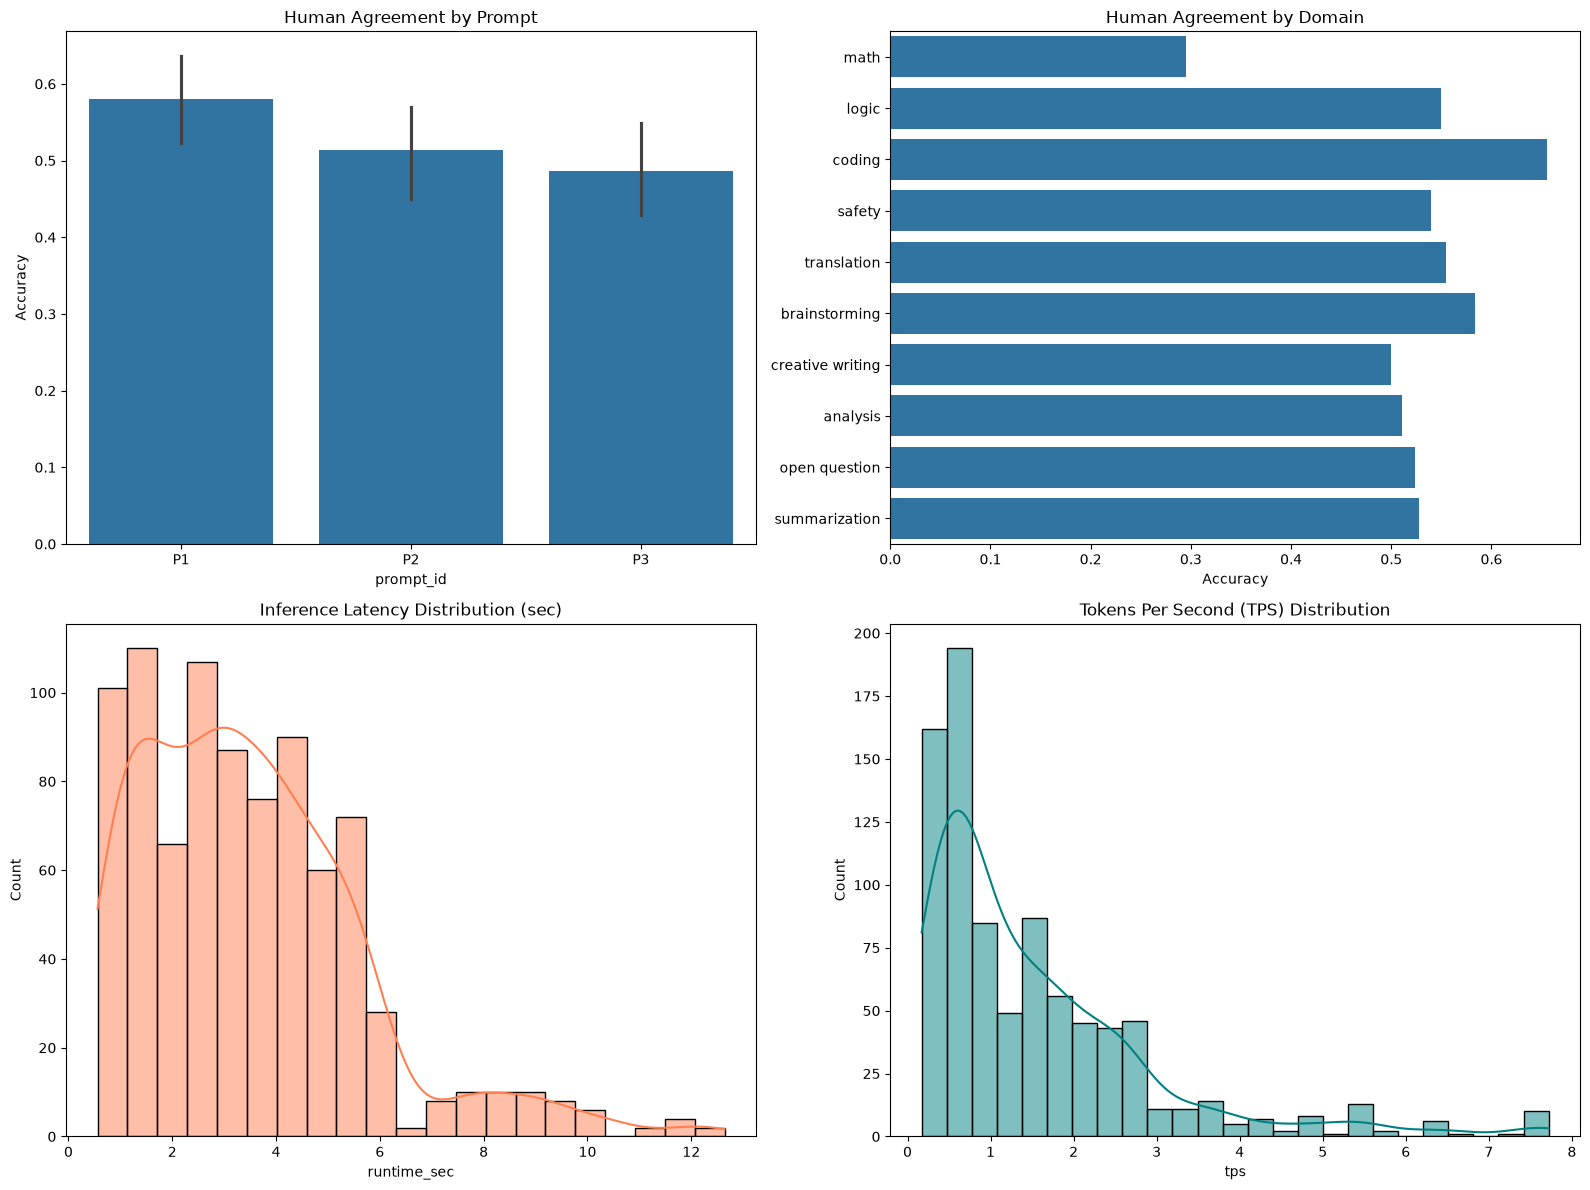

In [6]:
import re
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.metrics import cohen_kappa_score

# Membaca kembali hasil dari JSONL (Best Practice: Stateless Metric Evaluation)
RESULTS_DIR = '/content/drive/MyDrive/LLMReliability/results'
pilot_results_path = os.path.join(RESULTS_DIR, 'pilot_outputs.jsonl')

loaded_results = []
try:
    with open(pilot_results_path, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                loaded_results.append(json.loads(line))
    print(f"[INFO] Berhasil memuat {len(loaded_results)} record dari {pilot_results_path}\n")
except FileNotFoundError:
    print(f"[ERROR] File log tidak ditemukan di {pilot_results_path}. Pastikan inferensi telah dijalankan.")
    loaded_results = []

def parse_decision(raw_output: str) -> str:
    clean_text = raw_output.strip().upper()
    match = re.search(r'\b([AB])\b', clean_text)
    if match:
        return match.group(1)
    return "INVALID"

for r in loaded_results:
    parsed = parse_decision(r["raw_output"])
    r["parsed_decision"] = parsed
    
    # Inverse Mapping: Konversi 'A'/'B' kembali ke label riil 'Model 1' atau 'Model 2'
    if parsed == "INVALID":
        r["logical_decision"] = "INVALID"
    elif r["position"] == "AB":
        r["logical_decision"] = 1 if parsed == "A" else 2
    else: # BA: A artinya response_2
        r["logical_decision"] = 2 if parsed == "A" else 1
        
    # Same mapping for human preference logic (1 or 2)
    if r["position"] == "AB":
        r["logical_human"] = 1 if r["human_preference"] == "A" else 2
    else:
        r["logical_human"] = 2 if r["human_preference"] == "A" else 1

df_results = pd.DataFrame(loaded_results)

if not df_results.empty:
    # 1. Parsing Health
    invalid_rate = (len(df_results[df_results['parsed_decision'] == 'INVALID']) / len(df_results)) * 100
    print(f"=== PARSING HEALTH ===")
    print(f"Total Inferences: {len(df_results)}")
    print(f"Invalid Parsing: {invalid_rate:.1f}%\n")

    # Hanya gunakan yang valid untuk metrik sains
    df_valid = df_results[df_results['parsed_decision'] != 'INVALID'].copy()

    # 2. Accuracy & Cohen's Kappa (Human Agreement)
    accuracy = (df_valid['logical_decision'] == df_valid['logical_human']).mean() * 100
    kappa = cohen_kappa_score(list(df_valid['logical_decision']), list(df_valid['logical_human']))
    
    print("=== METRICS ANALYSIS (vs Human Preference) ===")
    print(f"Overall Human Agreement (Accuracy): {accuracy:.1f}%")
    print(f"Cohen's Kappa: {kappa:.3f} (0.0 = Random Guessing)\n")

    # 3. Position Flip Rate & Consistency
    pos_group = df_valid.groupby(['sample_id', 'prompt_id'])['logical_decision'].nunique()
    position_consistency = (pos_group == 1).mean() * 100
    position_flip_rate = 100 - position_consistency
    
    print("=== ROBUSTNESS ANALYSIS ===")
    print(f"Position Consistency Rate: {position_consistency:.1f}%")
    print(f"Position Flip Rate (Bias): {position_flip_rate:.1f}%\n")

    # 4. Prompt Flip Rate & Consistency
    prompt_group = df_valid.groupby(['sample_id', 'position'])['logical_decision'].nunique()
    prompt_consistency = (prompt_group == 1).mean() * 100
    prompt_flip_rate = 100 - prompt_consistency
    
    print(f"Prompt Consistency Rate: {prompt_consistency:.1f}%")
    print(f"Prompt Flip Rate (Bias): {prompt_flip_rate:.1f}%\n")

    # 5. Visualization Dashboard (4 Subplots)
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # A. Accuracy per Prompt
    sns.barplot(data=df_valid, x='prompt_id', y=(df_valid['logical_decision'] == df_valid['logical_human']).astype(int), ax=axes[0, 0])
    axes[0, 0].set_title('Human Agreement by Prompt')
    axes[0, 0].set_ylabel('Accuracy')

    # B. Accuracy per Domain
    df_valid['is_correct'] = (df_valid['logical_decision'] == df_valid['logical_human']).astype(int)
    sns.barplot(data=df_valid, x='is_correct', y='domain', orient='h', ax=axes[0, 1], errorbar=None)
    axes[0, 1].set_title('Human Agreement by Domain')
    axes[0, 1].set_xlabel('Accuracy')
    axes[0, 1].set_ylabel('')

    # C. Inference Latency Distribution
    sns.histplot(df_valid['runtime_sec'], kde=True, ax=axes[1, 0], color='coral')
    axes[1, 0].set_title('Inference Latency Distribution (sec)')

    # D. TPS Distribution
    sns.histplot(df_valid['tps'], kde=True, ax=axes[1, 1], color='teal')
    axes[1, 1].set_title('Tokens Per Second (TPS) Distribution')

    plt.tight_layout()
    plt.show()
else:
    print("[WARNING] Tidak ada data untuk divisualisasikan.")